In [1]:
import os
import numpy as np
import tifffile
import torch
import matplotlib.pyplot as plt
from skimage import exposure
from tqdm import tqdm

# ✅ Only standard SAM (this is correct)
from segment_anything import sam_model_registry, SamPredictor
# ✅ micro_sam utility (optional, will use later)
from micro_sam.util import precompute_image_embeddings,get_sam_model

# --- CONFIGURATION ---
CHECKPOINT_PATH = r'/work/scratch/rawat/image-segmentation-thesis/weight/sam_vit_h_4b8939.pth'
MODEL_TYPE = "vit_h"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# REPLACE THESE WITH YOUR EXACT FILE NAMES
IMAGE_PATH = r"/home/students/rawat/czi_output/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1.ome.tif"
MANUAL_ANNOTATION_PATH = r"/home/students/rawat/czi_output/Annotations/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1/Butons_Labels.tif"
OUTPUT_PATH = r"/home/students/rawat/czi_output/Annotations/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1/Brain1_FineTuned_Result.tif"
SAVE_ROOT = r"/home/students/rawat/czi_output/models/my_bouton_model"

# --- TRAINING SETTINGS ---
BATCH_SIZE = 2       # Reduce to 1 if you hit OOM (Out Of Memory)
PATCH_SHAPE = (512, 512) 
N_EPOCHS = 25

print(f"Checking for weights at: {CHECKPOINT_PATH}")
if os.path.exists(CHECKPOINT_PATH):
    print("✅ Weights file found.")
else:
    print("❌ Weights file NOT found. Check the path.")

print(f"Using device: {DEVICE}")

Checking for weights at: /work/scratch/rawat/image-segmentation-thesis/weight/sam_vit_h_4b8939.pth
✅ Weights file found.
Using device: cuda


In [2]:
## Verify axis order from OME metadata
with tifffile.TiffFile(IMAGE_PATH) as tif:
    # Attempt to read OME-XML metadata which holds the axis order
    if tif.ome_metadata:
        try:
            # tif.series[0].axes provides the axis order, e.g., 'CZYX'
            raw_axis_order = tif.series[0].axes
            print(f"✅ Metadata Axis Order: {raw_axis_order}")
            
            # Now we know how to transpose definitively!
            # Example: if raw_axis_order is 'CZYX', transpose to (1, 2, 3, 0)
            
        except Exception:
            print("ℹ️ OME metadata found, but axis order could not be read easily.")
    else:
        print("❌ OME metadata not found. The axis order cannot be determined automatically.")

✅ Metadata Axis Order: CZYX


In [3]:
# =========================
# LOAD IMAGE + GT
# =========================

print(f"Loading image from: {IMAGE_PATH}")
raw_data = tifffile.imread(IMAGE_PATH)

print(f"Loading manual annotation from: {MANUAL_ANNOTATION_PATH}")
manual_labels = tifffile.imread(MANUAL_ANNOTATION_PATH)

print(f"Raw image shape: {raw_data.shape}")
print(f"Manual mask shape: {manual_labels.shape}")


# =========================
# FORCE DATA INTO (Z, Y, X, C)
# =========================

if raw_data.ndim == 4:
    # Common microscopy cases:
    # (C, Z, Y, X) OR (Z, C, Y, X)

    if raw_data.shape[0] <= 4:  # (C, Z, Y, X)
        raw_data = np.transpose(raw_data, (1, 2, 3, 0))
        print("✅ Converted from (C, Z, Y, X) → (Z, Y, X, C)")

    elif raw_data.shape[1] <= 4:  # (Z, C, Y, X)
        raw_data = np.transpose(raw_data, (0, 2, 3, 1))
        print("✅ Converted from (Z, C, Y, X) → (Z, Y, X, C)")

else:
    raise ValueError("❌ Your image is not a 4D stack. Expected Z,Y,X,C.")


# =========================
# FORCE 3 CHANNELS (RGB)
# =========================

Z, Y, X, C = raw_data.shape
print(f"Reformatted shape: {raw_data.shape}")

if C == 1:
    raw_data = np.repeat(raw_data, 3, axis=-1)
    print("✅ Expanded 1 channel → 3 channels")

elif C == 2:
    pad = np.zeros((Z, Y, X, 1), dtype=raw_data.dtype)
    raw_data = np.concatenate([raw_data, pad], axis=-1)
    print("✅ Expanded 2 channels → 3 channels")

elif C > 3:
    raw_data = raw_data[..., :3]
    print("✅ Truncated extra channels → first 3 only")

print(f"✅ Final SAM input shape: {raw_data.shape}")

Loading image from: /home/students/rawat/czi_output/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1.ome.tif
Loading manual annotation from: /home/students/rawat/czi_output/Annotations/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1/Butons_Labels.tif
Raw image shape: (3, 92, 1431, 1431)
Manual mask shape: (92, 1431, 1431)
✅ Converted from (C, Z, Y, X) → (Z, Y, X, C)
Reformatted shape: (92, 1431, 1431, 3)
✅ Final SAM input shape: (92, 1431, 1431, 3)


In [4]:
Z, Y, X, C = raw_data.shape
print(f"Reformatted shape: {raw_data.shape}")

# 1. SELECT THE BOUTON CHANNEL
BOUTON_CHANNEL_INDEX = 0 
print(f"Isolating channel {BOUTON_CHANNEL_INDEX} (GFP/Boutons)...")

# Take only the green channel. Shape becomes (Z, Y, X)
bouton_data = raw_data[..., BOUTON_CHANNEL_INDEX]

# 2. ENHANCE CONTRAST (Crucial for SAM)
# Microscopy data is often 16-bit and dark. We stretch the brightness.
print("Enhancing contrast...")
p2, p99 = np.percentile(bouton_data, (2, 99))  # Ignore top/bottom 1% outliers
bouton_data_norm = exposure.rescale_intensity(
    bouton_data, 
    in_range=(p2, p99), 
    out_range=(0, 255)
).astype(np.uint8)

# 3. STACK TO 3 CHANNELS (Grayscale RGB)
# SAM requires 3 input channels. We repeat the enhanced green channel 3 times.
# This forces SAM to "see" only the green structures.
raw_data_rgb = np.stack((bouton_data_norm,)*3, axis=-1)

print(f"✅ Final SAM input shape: {raw_data_rgb.shape}")
print("   (Data is now 8-bit, high-contrast, and contains ONLY the bouton signal)")

Reformatted shape: (92, 1431, 1431, 3)
Isolating channel 0 (GFP/Boutons)...
Enhancing contrast...
✅ Final SAM input shape: (92, 1431, 1431, 3)
   (Data is now 8-bit, high-contrast, and contains ONLY the bouton signal)


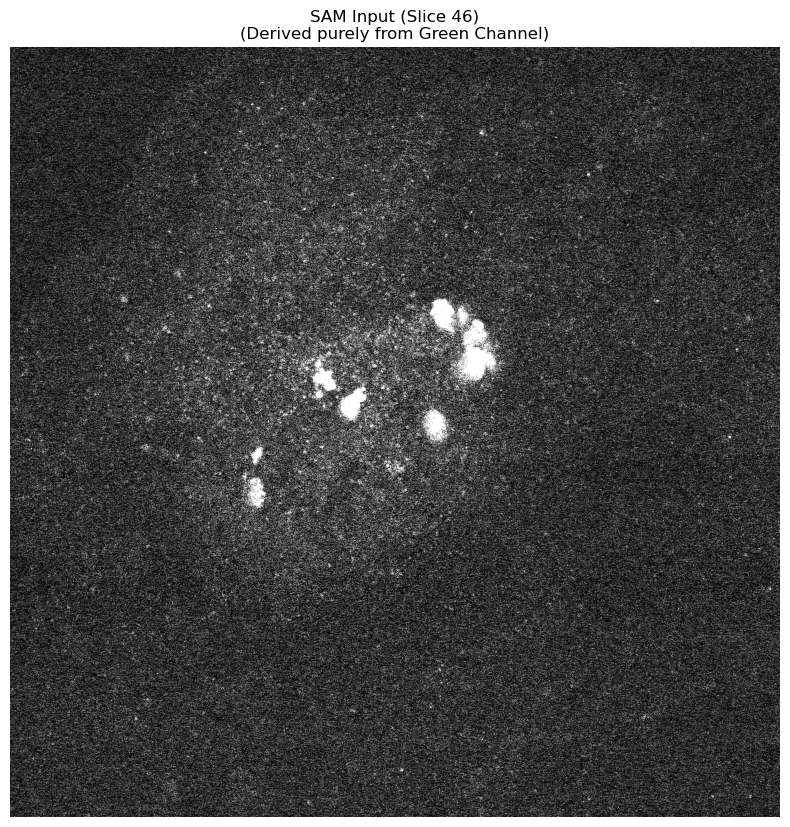

--- DATA INSPECTION ---
✅ Current Shape: (92, 1431, 1431, 3) (Z, Y, X, 3)
✅ VERIFIED: All 3 channels are identical.
   The image effectively contains ONLY the Green channel signal.
   (mCherry and Synapsin signals have been completely removed).


In [5]:
# 1. Select a middle slice to check
z_idx = raw_data_rgb.shape[0] // 2
slice_to_view = raw_data_rgb[z_idx]

# 2. VISUALIZE
plt.figure(figsize=(10, 10))
# Since R=G=B, imshow will display this as a Grayscale image
plt.imshow(slice_to_view) 
plt.title(f"SAM Input (Slice {z_idx})\n(Derived purely from Green Channel)")
plt.axis("off")
plt.show()

# 3. VERIFY MATHEMATICALLY
print("--- DATA INSPECTION ---")
print(f"✅ Current Shape: {raw_data.shape} (Z, Y, X, 3)")

# Check if Channel 0 (Red) is exactly equal to Channel 1 (Green) and Channel 2 (Blue)
# If they are equal, it means we successfully threw away the other signals.
is_duplicate = np.array_equal(slice_to_view[..., 0], slice_to_view[..., 1]) and \
               np.array_equal(slice_to_view[..., 1], slice_to_view[..., 2])

if is_duplicate:
    print("✅ VERIFIED: All 3 channels are identical.")
    print("   The image effectively contains ONLY the Green channel signal.")
    print("   (mCherry and Synapsin signals have been completely removed).")
else:
    print("❌ WARNING: Channels are different! Other signals might still be present.")

In [6]:
# --- Filter Empty Slices ---
x_slices = []
y_slices = []

print("Filtering empty slices...")
for z in range(raw_data_rgb.shape[0]):
    img_slice = raw_data_rgb[z] # (Y, X, 3)
    lbl_slice = manual_labels[z]       # (Y, X)
    
    # Only train on slices that actually have ground truth annotations
    if np.max(lbl_slice) > 0:
        x_slices.append(img_slice)
        y_slices.append(lbl_slice)

print(f"✅ Found {len(x_slices)} annotated slices for training.")

Filtering empty slices...
✅ Found 87 annotated slices for training.


In [7]:
from sklearn.model_selection import train_test_split
from micro_sam.training import default_sam_loader, train_sam

# --- Train/Validation Split ---
x_train, x_val, y_train, y_val = train_test_split(x_slices, y_slices, test_size=0.1, random_state=42)
print(f"Training on {len(x_train)} slices, Validating on {len(x_val)} slices.")

# =========================
# 3. SAVE DATA TO DISK (Fix for TypeError)
# =========================
# The loader requires file paths, not numpy arrays. 
# We save the slices to a temporary folder inside your SAVE_ROOT.

print("Saving training data to disk...")

def save_slices_to_disk(images, labels, root_dir, subset_name):
    # Create folders: e.g., models/my_bouton_model/data/train/images
    img_dir = os.path.join(root_dir, "data", subset_name, "images")
    lbl_dir = os.path.join(root_dir, "data", subset_name, "labels")
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    
    img_paths = []
    lbl_paths = []
    
    for i, (img, lbl) in enumerate(zip(images, labels)):
        # Filename: slice_001.tif
        fname = f"slice_{i:03d}.tif"
        img_path = os.path.join(img_dir, fname)
        lbl_path = os.path.join(lbl_dir, fname)
        
        tifffile.imwrite(img_path, img)
        tifffile.imwrite(lbl_path, lbl)
        
        img_paths.append(img_path)
        lbl_paths.append(lbl_path)
        
    return img_paths, lbl_paths

# Save Train Data
train_raw_paths, train_label_paths = save_slices_to_disk(x_train, y_train, SAVE_ROOT, "train")
# Save Val Data
val_raw_paths, val_label_paths = save_slices_to_disk(x_val, y_val, SAVE_ROOT, "val")

print("✅ Data saved to disk.")

# =========================
# 4. CREATE DATA LOADERS
# =========================
print("Creating DataLoaders...")

# Now we pass the PATHS (List of strings), not the arrays.
train_loader = default_sam_loader(
    raw_paths=train_raw_paths,    # <--- Now a list of file paths
    raw_key=None,
    label_paths=train_label_paths, # <--- Now a list of file paths
    label_key=None,
    patch_shape=PATCH_SHAPE,
    batch_size=BATCH_SIZE,
    with_segmentation_decoder=True, 
    shuffle=True
)

val_loader = default_sam_loader(
    raw_paths=val_raw_paths,
    raw_key=None,
    label_paths=val_label_paths,
    label_key=None,
    patch_shape=PATCH_SHAPE,
    batch_size=BATCH_SIZE,
    with_segmentation_decoder=True,
    shuffle=False
)

2025-12-10 10:15:25.635574: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765358125.650597  881718 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765358125.655701  881718 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/work/scratch/rawat/installations/conda/envs/thesis_microglomeruli/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training on 78 slices, Validating on 9 slices.
Saving training data to disk...
✅ Data saved to disk.
Creating DataLoaders...


In [8]:
# =========================
# 4. START TRAINING
# =========================
print("🚀 Starting Training Loop...")
print(f"Model will be saved to: {SAVE_ROOT}")

# The 'train_sam' function runs the interactive simulation loop
train_sam(
    name="best_bouton_model",
    model_type=MODEL_TYPE,
    train_loader=train_loader,
    val_loader=val_loader,
    n_epochs=N_EPOCHS,
    save_root=SAVE_ROOT,
    checkpoint_path=CHECKPOINT_PATH,
    device=DEVICE,
)

print("✅ Training Complete!")
print(f"New model path: {os.path.join(SAVE_ROOT, 'checkpoints', 'best_bouton_model', 'best.pt')}")

🚀 Starting Training Loop...
Model will be saved to: /home/students/rawat/czi_output/models/my_bouton_model


Verifying labels in 'val' dataloader: 100%|██████████| 50/50 [00:03<00:00, 12.57it/s]


Start fitting for 1250 iterations /  25 epochs
with 50 iterations per epoch
Training with mixed precision


Epoch 0:   0%|          | 0/1250 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 24.00 MiB. GPU 0 has a total capacity of 11.90 GiB of which 13.62 MiB is free. Including non-PyTorch memory, this process has 11.87 GiB memory in use. Of the allocated memory 11.49 GiB is allocated by PyTorch, and 216.74 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [7]:
# =========================
# LOAD SAM MODEL
# =========================

print(f"Loading SAM model ({MODEL_TYPE})...")
# This downloads the weights automatically if you don't have them
predictor = get_sam_model(model_type=MODEL_TYPE, device=DEVICE)

Loading SAM model (vit_h)...


In [9]:
from segment_anything import SamAutomaticMaskGenerator
print("🚀 Starting Automatic 3D Instance Segmentation...")
print("This may take a while depending on your GPU memory and volume size.")

# 'pred_iou_thresh': Confidence threshold (0.0 to 1.0). 
# Higher (e.g., 0.88) = fewer, but higher quality objects.
# Lower (e.g., 0.75) = finds more objects, but might include noise.
amg = SamAutomaticMaskGenerator(
    model=predictor.model,
    points_per_side=32,       # Grid density
    pred_iou_thresh=0.86,     # Confidence threshold (0.86 is standard, lower to 0.80 if it misses boutons)
    stability_score_thresh=0.92,
    min_mask_region_area=50,  # Ignore noise smaller than 50 pixels
)

🚀 Starting Automatic 3D Instance Segmentation...
This may take a while depending on your GPU memory and volume size.


In [ ]:
# 4. Run Segmentation
print("Running segmentation on Green Channel...")
# Create 3D Volume for results (Integers only, no channels)
final_prediction = np.zeros(bouton_data.shape, dtype=np.uint16)

for z in tqdm(range(bouton_data.shape[0]), desc="Segmenting"):
    img_slice = bouton_input[z] # (Y, X, 3)
    
    masks = amg.generate(img_slice)
    
    label_slice = np.zeros(img_slice.shape[:2], dtype=np.uint16)
    for i, mask_data in enumerate(masks):
        mask = mask_data['segmentation']
        # Assign ID (1, 2, 3...). Background remains 0.
        label_slice[mask] = i + 1 
        
    final_prediction[z] = label_slice



Running segmentation on Green Channel...


Segmenting: 100%|██████████| 92/92 [11:36<00:00,  7.58s/it]


NameError: name 'OUTPUT_PATH' is not defined

In [11]:
# 5. Save
OUTPUT_PATH = r'/home/students/rawat/czi_output/Annotations/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1/Brain1_Auto3D.tif'
print(f"Saving to {OUTPUT_PATH}")
tifffile.imwrite(OUTPUT_PATH, final_prediction)
print("Done. Check the file in Napari.")

Saving to /home/students/rawat/czi_output/Annotations/PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1/Brain1_Auto3D.tif
Done. Check the file in Napari.
